In [1]:
# To simulate a CR event, you must provide the details of zenith, azimuth, and energy here
# If you have shower-core information, before running CORSIKA, the corresponding antennas must be coordinate-transformed.
# That is : CORSIKA considers the shower core at the origin, move the origin from the center of the detector layout to the shower core and define the antenna location.

In [ ]:
# Step 1
# RUN prepare.sh file : ./prepare.sh EVENT_ID ZENITHS AZIMUTHS ENERGY_GEV SEED STORAGE_DIR
# 


Saved shifted antennas to /user/knivedita/SOFTWARE/output_files/make_corsika/O1e16.0z0a0/antenna.list


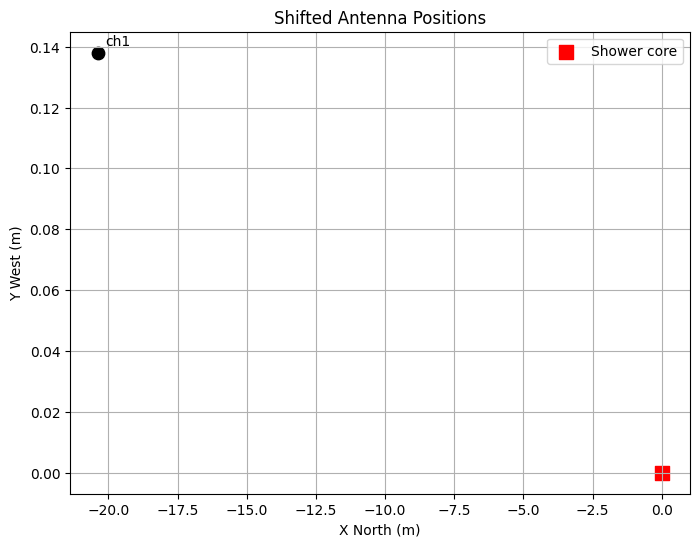

In [9]:
import matplotlib.pyplot as plt

# Original antenna positions in centimetres
coords = {
    "ch1": (-3036.7, 13.8),
}

# Shower-core position in metres
core_x = -10.0
core_y = 0.0

# Antenna height/depth in centimetres
z_cm = 319000.0

# Convert shower core to centimetres
core_x_cm = core_x * 100
core_y_cm = core_y * 100

shifted_coords = {}

for label, (x_cm, y_cm) in coords.items():
    shifted_x_cm = x_cm - core_x_cm
    shifted_y_cm = y_cm - core_y_cm

    shifted_coords[label] = (shifted_x_cm, shifted_y_cm)

# Write the shifted antennas
antenna_file = "/user/knivedita/SOFTWARE/output_files/make_corsika/O1e16.0z0a0/antenna.list"

with open(antenna_file, "w") as file:
    for label, (x_cm, y_cm) in shifted_coords.items():
        file.write(
            f"AntennaPosition = "
            f"{x_cm:.1f} {y_cm:.1f} {z_cm:.1f} {label}\n"
        )

print(f"Saved shifted antennas to {antenna_file}")

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

# Plot shifted antennas
for label, (x_cm, y_cm) in shifted_coords.items():
    x_m = x_cm / 100
    y_m = y_cm / 100

    ax.scatter(x_m, y_m, s=80, color="black")
    ax.annotate(
        label,
        (x_m, y_m),
        xytext=(5, 5),
        textcoords="offset points"
    )

# Shower core is the new origin
ax.scatter(
    0,
    0,
    s=100,
    color="red",
    marker="s",
    label="Shower core"
)

ax.set_xlabel("X North (m)")
ax.set_ylabel("Y West (m)")
ax.set_title("Shifted Antenna Positions")
ax.grid(True)

ax.legend()

plt.show()